---
title: "Ewolucja energii a orientacja siatki obliczeniowej"
author: "Jan Parszutowicz"
date: "2026-11-21"
lang: pl
format:
  pdf:
    fig-format: pdf
    number-sections: true
    geometry:
      - top=22mm
      - bottom=22mm
      - left=18mm
      - right=18mm
    include-in-header:
      text: |
        \usepackage{fvextra}
        \fvset{breaklines=true}
        \RedeclareSectionCommand[beforeskip=7pt, afterskip=3pt]{section}
        \RedeclareSectionCommand[beforeskip=4pt, afterskip=1pt]{subsection}
        \setlength{\abovecaptionskip}{3pt}
        \setlength{\belowcaptionskip}{2pt}
        \setlength{\textfloatsep}{8pt}
        \setlength{\parskip}{3pt}
        \setlength{\parindent}{0pt}
execute: true
---

# Założenia i przebieg eksperymentu

W projekcie badano wpływ orientacji układu na ewolucję energii kinetycznej. Symulację przeprowadzono wykorzystując pakiet $\texttt{PyMPDATA}$. Przestrzeń o wymiarach $1.45 \times 1.45 \, \mathrm{m}$, początkowo wypełnioną cieczą $h = 0.01\, \mathrm{m}$ wzbudzono umieszczając cylindryczną kroplę o promieniu $r=0.20 \, \mathrm{m}$ i wysokości $h=0.05 \, \mathrm{m}$. Ustanowiwszy stałe pole basenu manipulowano jego orientacją względem siatki obliczeniowej. Porównano dwie konfiguracje: obszar ustawiony zgodnie z kierunkiem krawędzi siatki oraz obrócony o **$45^\circ$**. Wykorzystano solwer rozwiązujący równania płytkiej wody -- który wzbogacono o liniowe tarcie denne $\vec{u}^{n+1} = \vec{u}^n \mathrm{e}^{-k\Delta t}$ ($k=0.2 \, \mathrm{s^{-1}}$). Warunki brzegowe traktowały krawędź basenu jako nieprzepuszczalny obszar, odpowiadający zekstrapolowanej wysokości słupa cieczy z sąsiednich, wewnętrznych komórek. 

# Dobór kroku czasowego

Przed właściwym porównaniem wykonano cztery symulacje z różnymi wielkościami kroku czasowego $\Delta t$ -- dla basenu zorientowanego zgodnie z kierunkiem krawędzi siatki. Siatkę zainicjowano o rozdzielczości $N=45 \times 45$. Przebieg całkowitej energii kinetycznej układu oraz ilustrację zbieżności przedstawia @fig-zbieznosc-czas, gdzie $E_{\mathrm{kin}} = \frac{1}{2} \rho \Delta x \Delta y \sum_{(i,j) \in \Omega_w} \frac{(uh)_{i,j}^2 + (vh)_{i,j}^2}{h_{i,j}}$, przy $\rho=1000 \, \mathrm{kg/m^3}$.

In [17]:
#| echo: false
#| output: false
#| warning: false

import os
os.environ['NUMBA_THREADING_LAYER'] = 'workqueue'

import numpy as np
import matplotlib.pyplot as plt
from PyMPDATA import ScalarField, Solver, Stepper, VectorField, Options, boundary_conditions
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('png', 'pdf')

In [ ]:
#| echo: false
#| output: false
#| warning: false

class ShallowWaterEquationsIntegrator:
    def __init__(self, *, h0, mask, g=9.81, bottom_friction=0.2, rho=1000.0, eps=1e-4, options=None):
        options = options or Options(nonoscillatory=True, infinite_gauge=True)
        X, Y, grid = 0, 1, h0.shape
        self.grid = grid
        self.mask = mask
        self.g = g
        self.bottom_friction = bottom_friction
        self.rho = rho
        self.eps = eps
        
        stepper = Stepper(options=options, grid=grid)
        boundary_cond = [boundary_conditions.Constant(value=0)] * len(grid)
        
        h_init = np.where(self.mask, h0, 0.0)
        
        advectees = { 
            "h": ScalarField(h_init, options.n_halo, boundary_cond),
            "uh": ScalarField(np.zeros(grid), options.n_halo, boundary_cond),
            "vh": ScalarField(np.zeros(grid), options.n_halo, boundary_cond),
        }
        self.advector = VectorField((
                np.zeros((grid[X] + 1, grid[Y])),
                np.zeros((grid[X], grid[Y] + 1))
            ), options.n_halo, boundary_cond 
        )
        self.solvers = { k: Solver(stepper, v, self.advector) for k, v in advectees.items() }
        
    def __getitem__(self, key):
        return self.solvers[key].advectee.get()
    
    def _apply_half_rhs(self, *, key, dt, axis, grid_step):
        h_ext = self['h'].copy()
        if axis == 0:
            wall_r = (~self.mask[1:, :]) & self.mask[:-1, :]
            h_ext[1:, :][wall_r] = h_ext[:-1, :][wall_r]
            wall_l = (~self.mask[:-1, :]) & self.mask[1:, :]
            h_ext[:-1, :][wall_l] = h_ext[1:, :][wall_l]
        else:
            wall_u = (~self.mask[:, 1:]) & self.mask[:, :-1]
            h_ext[:, 1:][wall_u] = h_ext[:, :-1][wall_u]
            wall_d = (~self.mask[:, :-1]) & self.mask[:, 1:]
            h_ext[:, :-1][wall_d] = h_ext[:, 1:][wall_d]

        force = - self.g * (dt / 2) * self['h'] * np.gradient(h_ext, grid_step[axis], axis=axis)
        self[key][self.mask] += force[self.mask]

    def _update_courant_numbers(self, *, axis, key, dt, grid_step):
        water_mask = self.mask & (self['h'] > self.eps)
        velocity = np.where(water_mask, np.nan, 0.0)
        momentum = self[key]
        np.divide(momentum, self['h'], where=water_mask, out=velocity)

        all = slice(None, None) 
        all_but_last = slice(None, -1)
        all_but_first_and_last = slice(1, -1)

        velocity_at_cell_boundaries = velocity[( 
            (all_but_last, all),
            (all, all_but_last),
        )[axis]] + np.diff(velocity, axis=axis) / 2 
        
        courant_number = self.advector.get_component(axis)[(
            (all_but_first_and_last, all),
            (all, all_but_first_and_last)
        )[axis]]
        
        courant_number[:] = velocity_at_cell_boundaries * dt / grid_step[axis]
        
        if axis == 0:
            valid_faces = self.mask[:-1, :] & self.mask[1:, :]
        else:
            valid_faces = self.mask[:, :-1] & self.mask[:, 1:]
            
        courant_number[~valid_faces] = 0.0
        assert np.amax(np.abs(courant_number)) <= 1.0

    def _apply_mask_walls_and_bottom_friction(self, dt):
        self['h'][~self.mask] = 0.0
        self['uh'][~self.mask] = 0.0
        self['vh'][~self.mask] = 0.0
        if self.bottom_friction > 0:
            decay = np.exp(-self.bottom_friction * dt)
            self['uh'][self.mask] *= decay
            self['vh'][self.mask] *= decay

    def get_kinetic_energy(self, grid_step):
        water = self.mask & (self['h'] > self.eps)
        h = self['h'][water]
        uh = self['uh'][water]
        vh = self['vh'][water]
        dx, dy = grid_step
        return 0.5 * self.rho * np.sum((uh**2 + vh**2) / h) * (dx * dy)

    def __call__(self, *, nt, grid_step, dt, outfreq):
        output = {'E_kin': [], 'time': []}
        for it in range(nt + 1): 
            if it != 0:
                for axis, key in enumerate(("uh", "vh")):
                    self._update_courant_numbers(axis=axis, key=key, dt=dt, grid_step=grid_step)
                self.solvers["h"].advance(n_steps=1)
                for axis, key in enumerate(("uh", "vh")):
                    self._apply_half_rhs(key=key, axis=axis, dt=dt, grid_step=grid_step)
                    self.solvers[key].advance(n_steps=1)
                    self._apply_half_rhs(key=key, axis=axis, dt=dt, grid_step=grid_step)
                self._apply_mask_walls_and_bottom_friction(dt=dt)
            if it % outfreq == 0:
                output['E_kin'].append(self.get_kinetic_energy(grid_step=grid_step))
                output['time'].append(it * dt)
        return output

In [ ]:
#| echo: false
#| output: false
#| warning: false

L_box = 2.25
L_pool = 1.45
R_drop = 0.20
H_base = 0.01
H_drop = 0.05

def create_setup(N, rotated=False):
    dx = L_box / N
    grid_step = (dx, dx)
    coords = (np.arange(N) - (N - 1) / 2) * dx
    X, Y = np.meshgrid(coords, coords, indexing='ij')
    R_half = L_pool / 2
    if not rotated:
        mask = (np.abs(X) <= R_half) & (np.abs(Y) <= R_half)
    else:
        X_rot = (X + Y) / np.sqrt(2)
        Y_rot = (-X + Y) / np.sqrt(2)
        mask = (np.abs(X_rot) <= R_half) & (np.abs(Y_rot) <= R_half)
    dist = np.sqrt(X**2 + Y**2)
    h0 = np.zeros((N, N))
    h0[mask] = H_base
    h0[mask & (dist <= R_drop + 1e-9)] = H_drop
    return h0, mask, grid_step

N_base = 45
h0_base, mask_base, grid_step_base = create_setup(N_base, rotated=False)

T_sim = 2.5
dt_values = [0.008, 0.004, 0.002, 0.001]
time_results = {}

for dt in dt_values:
    nt = int(T_sim / dt)
    outfreq = max(1, int(round(0.02 / dt)))
    solver = ShallowWaterEquationsIntegrator(h0=h0_base, mask=mask_base, g=9.81, bottom_friction=0.2)
    time_results[dt] = solver(nt=nt, grid_step=grid_step_base, dt=dt, outfreq=outfreq)

assert np.isclose(np.sum(h0_base), np.sum(solver['h']), rtol=1e-10)
assert np.all(solver['h'][~mask_base] == 0.0)

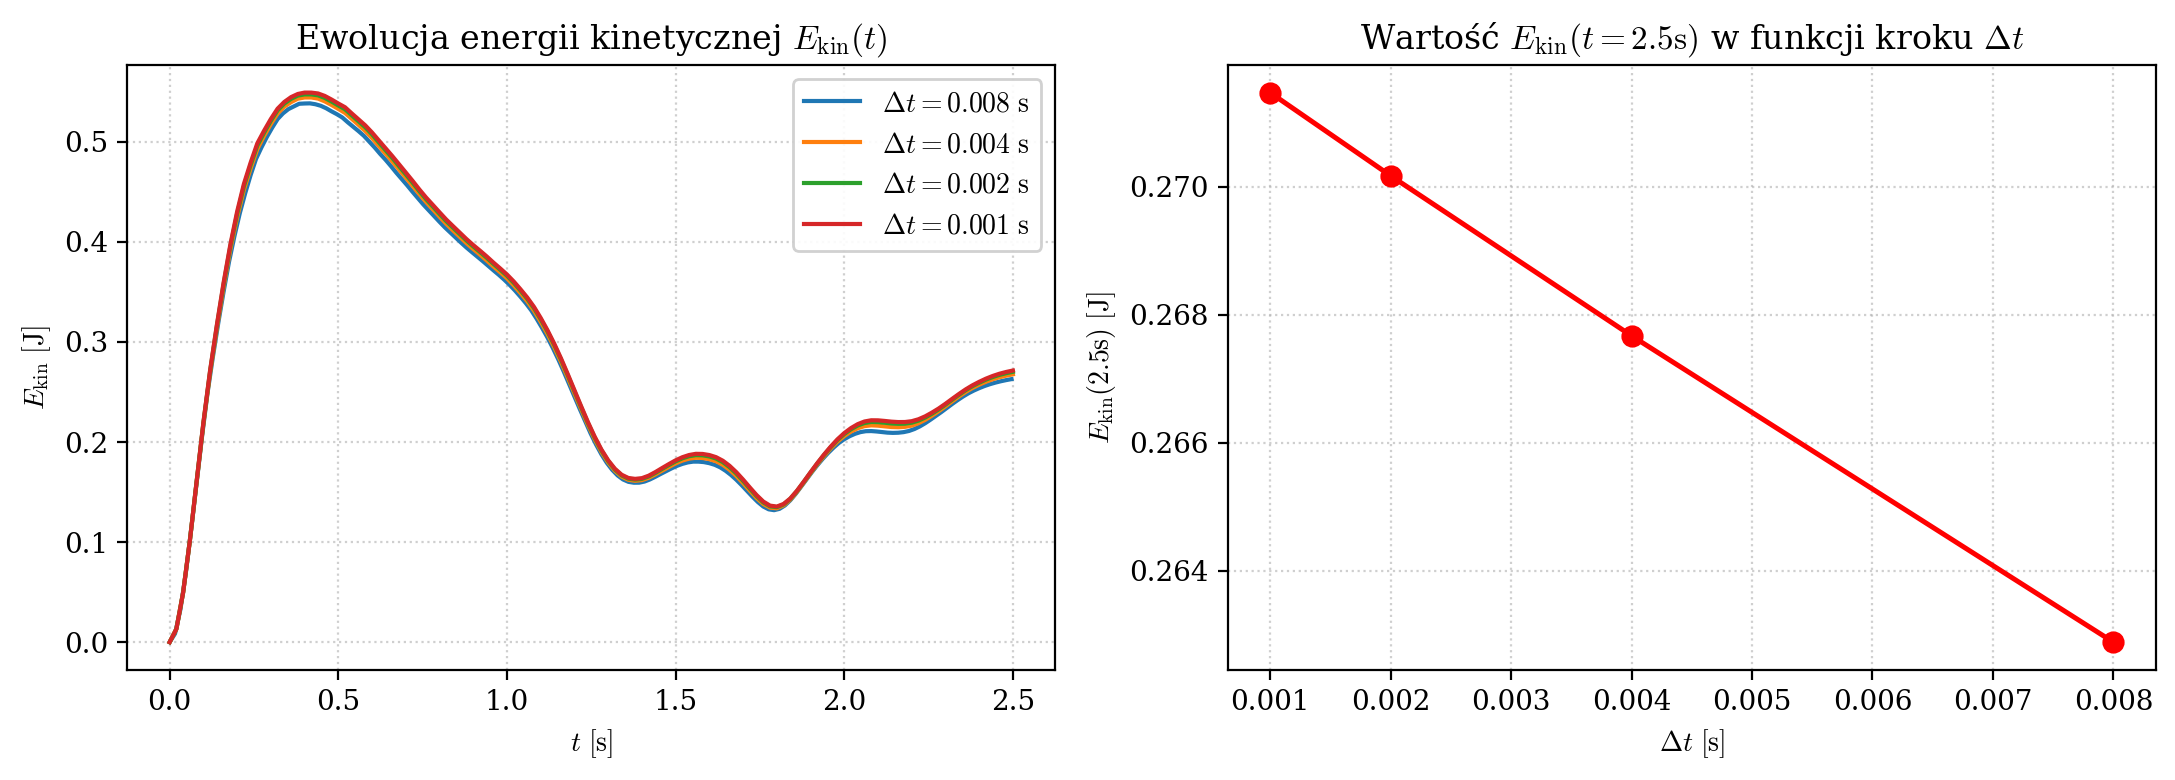

In [18]:
#| echo: false
#| fig-align: center
#| fig-cap: "Weryfikacja zbieżności czasowej: ewolucja energii kinetycznej (po lewej) oraz zależność energii końcowej od kroku czasowego (po prawej)."
#| label: fig-zbieznosc-czas

plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), dpi=200)

for dt in dt_values:
    ax1.plot(time_results[dt]['time'], time_results[dt]['E_kin'], label=rf'$\Delta t = {dt}\ \mathrm{{s}}$')

ax1.set_xlabel(r"$t\ [\mathrm{s}]$")
ax1.set_ylabel(r"$E_{\mathrm{kin}}\ [\mathrm{J}]$")
ax1.set_title(r"Ewolucja energii kinetycznej $E_{\mathrm{kin}}(t)$")
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(frameon=True, facecolor='white', framealpha=0.9)

E_final = [time_results[dt]['E_kin'][-1] for dt in dt_values]
ax2.plot(dt_values, E_final, 'o-', color='red', lw=1.8, markersize=7)
ax2.set_xlabel(r"$\Delta t\ [\mathrm{s}]$")
ax2.set_ylabel(r"$E_{\mathrm{kin}}(2.5\mathrm{s})\ [\mathrm{J}]$")
ax2.set_title(r"Wartość $E_{\mathrm{kin}}(t = 2.5\mathrm{s})$ w funkcji kroku $\Delta t$")
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

Modyfikacje kroku czasowego nie wpływają na charakter ewolucji energii kinetycznej. Na potrzeby dalszych symulacji ustawiono wielkość $\Delta t=0.002 \, \mathrm{s}$ -- mniejszy krok czasowy nie poprawia wyraźnie dokładności, wydłuża za to czas trwania obliczeń. 

# Basen obrócony - wpływ parametrów siatki

Porównanie z basenem obróconym wykonano dla trzech różnych rozmiarów siatki: $N = 31 \times 31$, $45 \times 45$, $65 \times 65$ -- zachowując stałe wymiary fizyczne basenu i początkowego wymuszenia. Zestawienie przebiegów energii kinetycznej w czasie oraz normę błędu $\varepsilon_{L_2}$ względem basenu nieobróconego (referencyjnego) przedstawia @fig-zbieznosc-siatka. 

In [ ]:
#| echo: false
#| output: false
#| warning: false

dt_fixed = 0.002
nt_spatial = int(T_sim / dt_fixed)

h0_ref, mask_ref, grid_step_ref = create_setup(65, rotated=False)
solver_ref = ShallowWaterEquationsIntegrator(h0=h0_ref, mask=mask_ref, g=9.81, bottom_friction=0.2)
spatial_reference = solver_ref(nt=nt_spatial, grid_step=grid_step_ref, dt=dt_fixed, outfreq=10)

spatial_resolutions = [31, 45, 65]
spatial_results = {}

for N in spatial_resolutions:
    h0_rot, mask_rot, grid_step_rot = create_setup(N, rotated=True)
    solver_rot = ShallowWaterEquationsIntegrator(h0=h0_rot, mask=mask_rot, g=9.81, bottom_friction=0.2)
    spatial_results[N] = solver_rot(nt=nt_spatial, grid_step=grid_step_rot, dt=dt_fixed, outfreq=10)

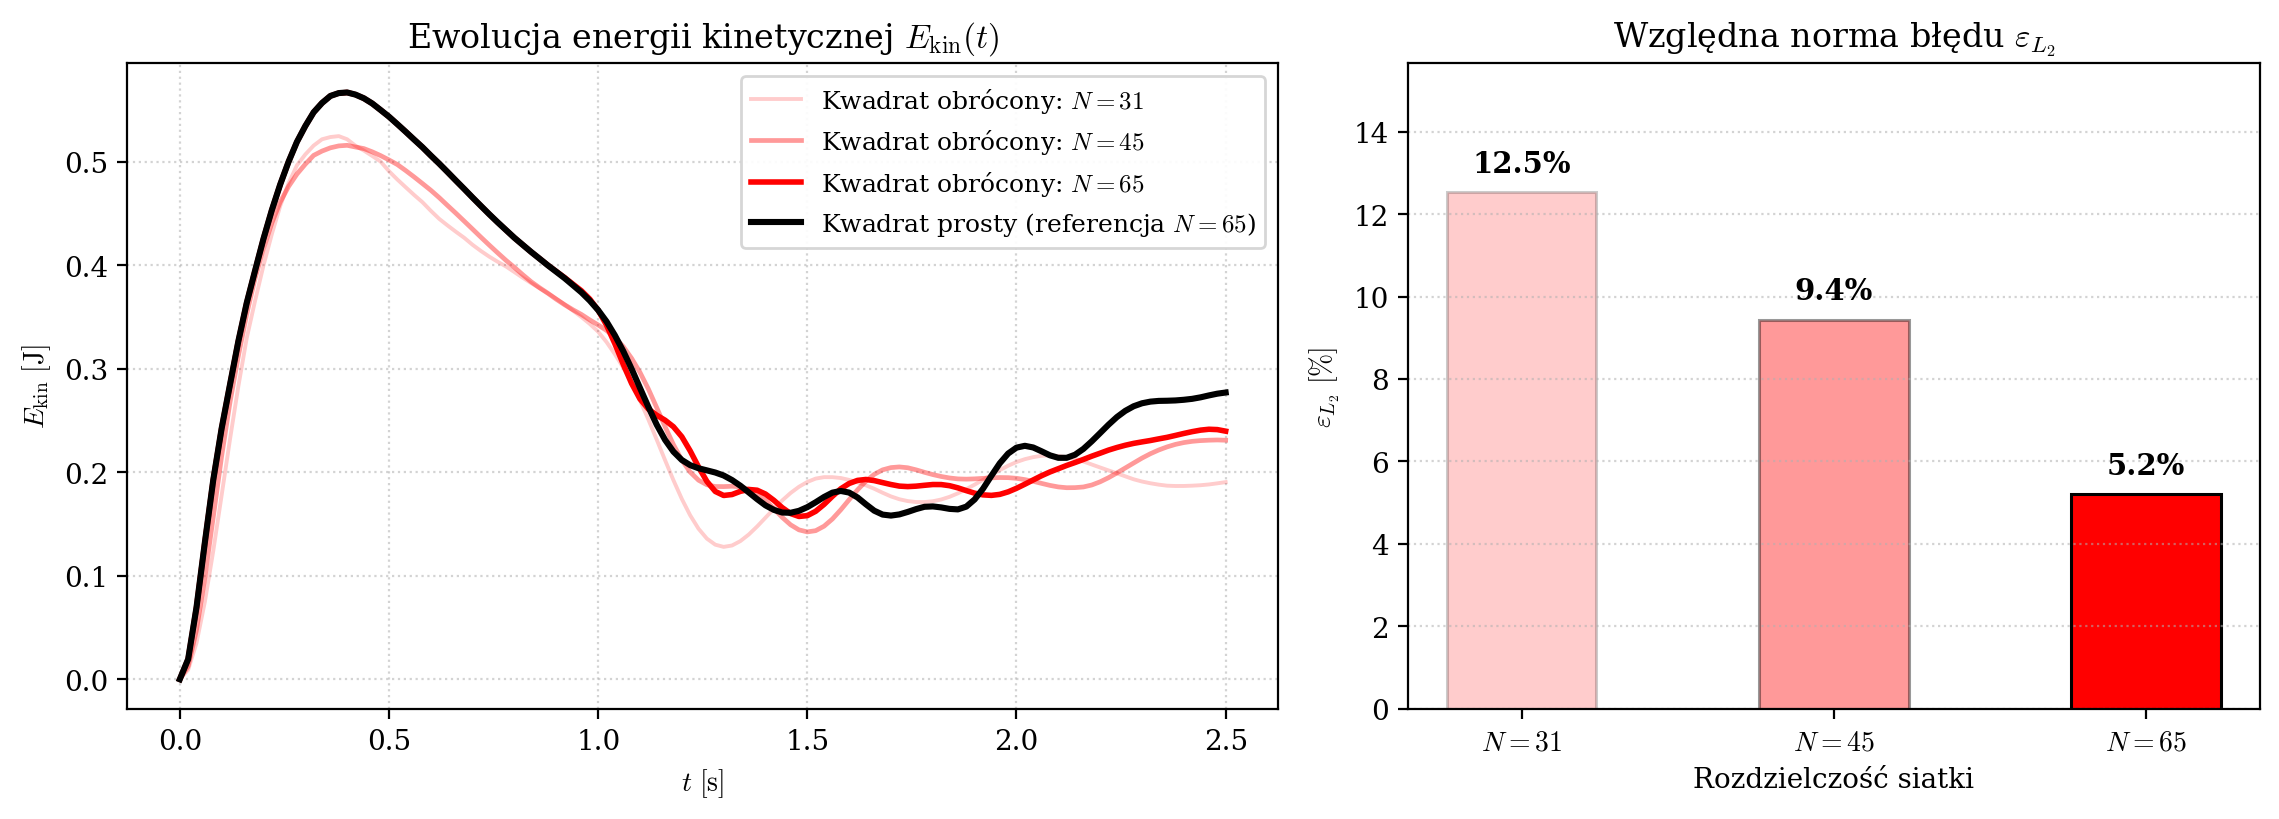

In [ ]:
#| echo: false
#| fig-align: center
#| fig-cap: "Wpływ orientacji siatki na dynamikę energii kinetycznej (po lewej) oraz względny błąd dyskretyzacji przestrzennej w normie L2 (po prawej)."
#| label: fig-zbieznosc-siatka

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2), dpi=200, gridspec_kw={'width_ratios': [1.35, 1.0]})

base_color = 'red'
mesh_styles = {
    31: {'alpha': 0.20, 'lw': 1.4, 'label': r'Kwadrat obrócony: $N = 31$'},
    45: {'alpha': 0.40, 'lw': 1.7, 'label': r'Kwadrat obrócony: $N = 45$'},
    65: {'alpha': 1.00, 'lw': 2.0, 'label': r'Kwadrat obrócony: $N = 65$'},
}

for N in spatial_resolutions:
    cfg = mesh_styles[N]
    ax1.plot(
        spatial_results[N]['time'],
        spatial_results[N]['E_kin'],
        color=base_color,
        alpha=cfg['alpha'],
        linewidth=cfg['lw'],
        label=cfg['label']
    )

ax1.plot(
    spatial_reference['time'],
    spatial_reference['E_kin'],
    color='black',
    linewidth=2.2,
    label=r'Kwadrat prosty (referencja $N = 65$)',
    zorder=5
)

ax1.set_xlabel(r"$t\ [\mathrm{s}]$")
ax1.set_ylabel(r"$E_{\mathrm{kin}}\ [\mathrm{J}]$")
ax1.set_title(r"Ewolucja energii kinetycznej $E_{\mathrm{kin}}(t)$")
ax1.grid(True, linestyle=':', alpha=0.55)
ax1.legend(frameon=True, facecolor='white', framealpha=0.92, edgecolor='lightgray', fontsize=9, loc='upper right')

E_ref = np.array(spatial_reference['E_kin'])
errors_L2 = [
    np.sqrt(np.sum((np.array(spatial_results[N]['E_kin']) - E_ref)**2) / np.sum(E_ref**2)) * 100
    for N in spatial_resolutions
]

assert errors_L2[2] < errors_L2[1] < errors_L2[0]

bar_labels = [rf'$N = {N}$' for N in spatial_resolutions]
bars = ax2.bar(bar_labels, errors_L2, color=base_color, width=0.48, edgecolor='black', linewidth=1.1)

for bar, N in zip(bars, spatial_resolutions):
    bar.set_alpha(mesh_styles[N]['alpha'])
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2.0, yval + 0.35, f"{yval:.1f}%", ha='center', va='bottom', fontsize=10.5, fontweight='bold', color='black')

ax2.set_xlabel(r"Rozdzielczość siatki")
ax2.set_ylabel(r"$\varepsilon_{L_2}\ [\%]$")
ax2.set_title(r"Względna norma błędu $\varepsilon_{L_2}$")
ax2.set_ylim(0, max(errors_L2) * 1.25)
ax2.grid(True, axis='y', linestyle=':', alpha=0.55)

plt.tight_layout()
plt.show()

Wraz ze zwiększaniem rozdzielczości $N$ charakter przebiegu energii przybliża się do referencyjnego. Maleje również względna norma błędu $\varepsilon_{L_2}$. Odpowiednio zagęszczona siatka obliczeniowa minimalizuje dynamiczne efekty zmiany orientacji układu.

# Bibliografia

1. Dokumentacja pakietu $\texttt{PyMPDATA}$: [https://open-atmos.github.io/PyMPDATA/](https://open-atmos.github.io/PyMPDATA/) [dostęp 21.11.2026]
2. Dokumentacja biblioteki $\texttt{Matplotlib}$ [https://matplotlib.org/stable/index.html](https://matplotlib.org/stable/index.html) [dostęp 21.11.2026]
3. Materiały z wykładu *Modelowanie układów przepływowych* -- dr hab. Sylwester Arabas, prof. AGH.